# Data Bank: ai nên được mời mở thẻ tín dụng?

**Bối cảnh.** CEO muốn đẩy mạnh cho vay khách hàng cá nhân. Ngân hàng đã có nhiều khách dùng thẻ thanh toán (debit), nhưng số lượng và dư nợ thẻ tín dụng còn thấp. Thẻ tín dụng là bước đầu tiên trên "bậc thang" sản phẩm cho vay: thẻ thanh toán → thẻ tín dụng → vay mua xe → vay mua nhà. Khách đã có lịch sử dùng thẻ tín dụng tốt thì dễ mời vay tiếp.

**Câu hỏi.** Trong số khách đang dùng tài khoản thanh toán, ai nên được mời chuyển sang thẻ tín dụng?

**Logic chọn khách.** Một khách phù hợp phải thỏa cả hai vế:
- **Có nhu cầu**: tiền ra (rút + chi tiêu) nhiều hơn tiền vào (nạp) mỗi tháng, tức dòng tiền ròng âm.
- **Có khả năng trả**: thu nhập đủ cao và phần thiếu hụt không vượt quá thu nhập.

Thêm một điều kiện về giá trị lâu dài: khách dưới 60 tuổi còn thời gian để ngân hàng bán chéo khoản vay mua xe, mua nhà.

**Dữ liệu.** 4 bảng của khóa học SQL ứng dụng trong tài chính: `customer_info` (700 khách), `customer_region`, `regions`, `customer_transactions` (giao dịch tháng 1 đến tháng 4/2020).

**Công cụ.** Bản chính viết bằng SQL Server (thư mục `sql/`). Notebook này chạy lại đúng các bước đó bằng **DuckDB** (SQL chạy ngay trong Python, không cần cài server) để vẽ biểu đồ.

In [1]:
import os
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
os.makedirs('figures', exist_ok=True)
os.makedirs('output', exist_ok=True)

BLUE = '#1F3A5F'
MINT = '#A9B8CC'
GREY = '#DDE2E9'

## 1. Đọc dữ liệu vào DuckDB

Nếu chạy trên Google Colab: bấm Run all, đến ô dưới sẽ hiện nút **Choose Files**, chọn cả 4 file `customer_info.csv`, `customer_region.csv`, `customer_transactions.csv`, `regions.csv`.

In [2]:
if os.path.exists('data/customer_info.csv'):
    folder = 'data/'
elif os.path.exists('customer_info.csv'):
    folder = ''
else:   # chạy trên Colab thì tải file lên
    from google.colab import files
    files.upload()
    folder = ''

con = duckdb.connect()
for table in ['customer_info', 'customer_region', 'customer_transactions', 'regions']:
    con.execute(f"CREATE OR REPLACE TABLE {table} AS SELECT * FROM read_csv_auto('{folder}{table}.csv')")


def sql(query):
    """Chạy câu SQL và trả về DataFrame."""
    return con.execute(query).df()


sql("""
SELECT 'customer_info' AS tbl, COUNT(*) AS n FROM customer_info
UNION ALL SELECT 'customer_region', COUNT(*) FROM customer_region
UNION ALL SELECT 'customer_transactions', COUNT(*) FROM customer_transactions
UNION ALL SELECT 'regions', COUNT(*) FROM regions
""")

,tbl,n
0,customer_info,700
1,customer_region,828
2,customer_transactions,5868
3,regions,5


In [3]:
sql("SELECT * FROM customer_info LIMIT 5")

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer
0,1,1957,Graduation,Single,58138,0,0,2012-04-09
1,2,1954,Graduation,Single,46344,1,1,2014-08-03
2,3,1965,Graduation,Together,71613,0,0,2013-08-21
3,4,1984,Graduation,Together,26646,1,0,2014-10-02
4,5,1981,PhD,Married,58293,1,0,2014-01-19


In [4]:
sql("SELECT * FROM customer_transactions LIMIT 5")

,customer_id,txn_date,txn_type,txn_amount
0,429,2020-01-21,deposit,820
1,155,2020-01-10,deposit,7120
2,398,2020-01-01,deposit,1960
3,255,2020-01-14,deposit,5630
4,185,2020-01-29,deposit,6260


## 2. Kiểm tra dữ liệu

Theo 4 câu hỏi: định dạng có đúng không, có giá trị bất thường không, có giá trị trống không, các bảng có khớp nhau không.

In [5]:
sql("SELECT MIN(txn_date) AS first_day, MAX(txn_date) AS last_day, COUNT(DISTINCT customer_id) AS customers FROM customer_transactions")

,first_day,last_day,customers
0,2020-01-01,2020-04-28,500


In [6]:
sql("SELECT txn_type, COUNT(*) AS n, MIN(txn_amount) AS min_amt, MAX(txn_amount) AS max_amt FROM customer_transactions GROUP BY txn_type")

,txn_type,n,min_amt,max_amt
0,deposit,2671,10,10000
1,withdrawal,1580,10,9990
2,purchase,1617,10,9990


In [7]:
print(sql("SELECT Education, COUNT(*) AS n FROM customer_info GROUP BY Education ORDER BY n DESC"))
print()
print(sql("SELECT Marital_Status, COUNT(*) AS n FROM customer_info GROUP BY Marital_Status ORDER BY n DESC"))

    Education    n
0  Graduation  358
1         PhD  149
2      Master  122
3    2n Cycle   59
4       Basic   12

  Marital_Status    n
0        Married  270
1       Together  171
2         Single  155
3       Divorced   77
4          Widow   24
5          Alone    3


- `2n Cycle` là bậc Master (theo chuẩn châu Âu: 1st cycle = Bachelor, 2nd cycle = Master, 3rd cycle = PhD).
- `Alone` (3 khách) cùng nghĩa với `Single`.

In [8]:
sql("""
SELECT MIN(Year_Birth) AS min_year, MAX(Year_Birth) AS max_year,
       MIN(Income) AS min_income, MAX(Income) AS max_income,
       SUM(CASE WHEN Income = 0 THEN 1 ELSE 0 END) AS income_zero
FROM customer_info
""")

,min_year,max_year,min_income,max_income,income_zero
0,1893,1996,0,157243,13.0


In [9]:
# Chính sách ngân hàng: chỉ mở thẻ cho khách dưới 70 tuổi
sql("""
SELECT ID, Year_Birth, Dt_Customer, YEAR(Dt_Customer) - Year_Birth AS age_at_open
FROM customer_info
WHERE YEAR(Dt_Customer) - Year_Birth > 70
""")

,ID,Year_Birth,Dt_Customer,age_at_open
0,193,1900,2013-09-26,113
1,240,1893,2014-05-17,121
2,340,1899,2013-09-26,114
3,416,1943,2014-03-31,71
4,425,1941,2013-04-13,72


In [10]:
checks = sql("""
SELECT
    (SELECT COUNT(*) FROM customer_region WHERE region_id NOT IN (SELECT region_id FROM regions)) AS no_region,
    (SELECT COUNT(*) FROM customer_info WHERE ID NOT IN (SELECT customer_id FROM customer_region)) AS info_without_region,
    (SELECT COUNT(*) FROM customer_info WHERE ID NOT IN (SELECT DISTINCT customer_id FROM customer_transactions)) AS no_transactions
""")
checks

,no_region,info_without_region,no_transactions
0,10,65,200


In [11]:
# Hồ sơ trùng: khác ID nhưng giống hệt các thông tin còn lại
sql("""
SELECT Year_Birth, Education, Marital_Status, Income, Dt_Customer, COUNT(*) AS n, LIST(ID) AS ids
FROM customer_info
GROUP BY Year_Birth, Education, Marital_Status, Income, Dt_Customer
HAVING COUNT(*) > 1
LIMIT 5
""")

,Year_Birth,Education,Marital_Status,Income,Dt_Customer,n,ids
0,1946,Graduation,Together,37760,2012-08-31,2,"[18, 283]"
1,1951,Graduation,Together,40689,2013-03-18,2,"[25, 582]"
2,1973,2n Cycle,Married,35688,2012-08-22,2,"[149, 384]"
3,1958,2n Cycle,Together,26490,2012-09-22,2,"[254, 658]"
4,1989,Graduation,Single,30279,2012-12-30,2,"[378, 444]"


**Kết quả kiểm tra:**
- 10 khách có `region_id = 6`, không có trong bảng `regions` → không xác định được châu lục, loại.
- 5 khách mở thẻ khi đã trên 70 tuổi (3 trong số đó có năm sinh 1893, 1899, 1900, rõ ràng sai) → loại theo chính sách.
- 200 khách (ID từ 501) không có giao dịch nào trong kỳ → không đánh giá được dòng tiền, loại.
- 13 khách có thu nhập = 0 → nhiều khả năng là thiếu dữ liệu, chuyển thành NULL để không kéo thấp thu nhập trung bình.
- 20 nhóm hồ sơ trùng thông tin nhưng giao dịch khác nhau → giữ lại, ghi chú để hỏi bộ phận dữ liệu.
- Tháng 4 chỉ có dữ liệu đến ngày 28.

## 3. Làm sạch dữ liệu

In [12]:
con.execute("""
CREATE OR REPLACE TABLE customer_clean AS
SELECT
      T1.ID
    , T1.Year_Birth
    , 2020 - T1.Year_Birth AS age
    , CASE WHEN T1.Education = '2n Cycle' THEN 'Master' ELSE T1.Education END AS education
    , CASE WHEN T1.Marital_Status = 'Alone' THEN 'Single' ELSE T1.Marital_Status END AS marital_status
    , NULLIF(T1.Income, 0) AS income
    , T1.Kidhome + T1.Teenhome AS children
    , T1.Dt_Customer
    , T3.region_name
    , CASE
        WHEN 2020 - T1.Year_Birth < 30 THEN '20-30'
        WHEN 2020 - T1.Year_Birth < 40 THEN '30-40'
        WHEN 2020 - T1.Year_Birth < 50 THEN '40-50'
        WHEN 2020 - T1.Year_Birth < 60 THEN '50-60'
        WHEN 2020 - T1.Year_Birth < 70 THEN '60-70'
        ELSE '70+'
      END AS age_group
FROM customer_info T1
JOIN customer_region T2 ON T1.ID = T2.customer_id
JOIN regions T3         ON T2.region_id = T3.region_id
WHERE YEAR(T1.Dt_Customer) - T1.Year_Birth <= 70
  AND T1.ID IN (SELECT DISTINCT customer_id FROM customer_transactions)
""")

con.execute("""
CREATE OR REPLACE TABLE transactions_clean AS
SELECT *
FROM customer_transactions
WHERE customer_id IN (SELECT ID FROM customer_clean)
""")

sql("SELECT (SELECT COUNT(*) FROM customer_clean) AS customers, (SELECT COUNT(*) FROM transactions_clean) AS transactions")

,customers,transactions
0,495,5798


## 4. Dòng tiền vào, ra của từng khách hàng

- Tiền vào = `deposit`, tiền ra = `withdrawal` + `purchase`.
- Cộng theo từng tháng, rồi lấy trung bình các tháng của mỗi khách.
- `net_flow` = tiền vào TB/tháng − tiền ra TB/tháng. Âm nghĩa là khách tiêu nhiều hơn số tiền nạp vào.

(Trên SQL Server dùng `EOMONTH(txn_date)`; DuckDB dùng `LAST_DAY(txn_date)`, cùng kết quả.)

In [13]:
con.execute("""
CREATE OR REPLACE TABLE customer_cashflow AS
WITH monthly AS (
    SELECT
          customer_id
        , LAST_DAY(txn_date) AS report_month
        , SUM(CASE WHEN txn_type = 'deposit' THEN txn_amount ELSE 0 END) AS money_in
        , SUM(CASE WHEN txn_type IN ('withdrawal', 'purchase') THEN txn_amount ELSE 0 END) AS money_out
    FROM transactions_clean
    GROUP BY customer_id, LAST_DAY(txn_date)
)
SELECT
      customer_id
    , COUNT(*) AS active_months
    , AVG(money_in) AS avg_in
    , AVG(money_out) AS avg_out
    , AVG(money_in) - AVG(money_out) AS net_flow
FROM monthly
GROUP BY customer_id
""")

con.execute("""
CREATE OR REPLACE TABLE customer_base AS
SELECT
      T1.*
    , T1.income / 12.0 AS monthly_income
    , T2.active_months
    , T2.avg_in
    , T2.avg_out
    , T2.net_flow
    , CASE WHEN T2.net_flow < 0 THEN 1 ELSE 0 END AS is_deficit
FROM customer_clean T1
JOIN customer_cashflow T2 ON T1.ID = T2.customer_id
""")

overall = sql("""
SELECT COUNT(*) AS customers,
       SUM(is_deficit) AS deficit_customers,
       AVG(is_deficit) * 100 AS pct_deficit,
       AVG(monthly_income) AS avg_monthly_income,
       MEDIAN(monthly_income) AS median_monthly_income
FROM customer_base
""")
overall.round(1)

,customers,deficit_customers,pct_deficit,avg_monthly_income,median_monthly_income
0,495,283.0,57.2,4267.4,4230.1


57% khách tiêu nhiều hơn số tiền nạp vào. Nhu cầu tín dụng khá rộng, nên câu hỏi quan trọng hơn là **ai trong số đó trả được nợ**.

Thu nhập trung vị khoảng 4.200 USD/tháng. Notebook dùng mốc **4.000 USD/tháng** làm ngưỡng thu nhập đủ cao (số tròn, gần trung vị).

## 5. Phân tích theo 5 chiều

Mỗi nhóm khách được xem trên 2 chỉ số: % khách thâm hụt (nhu cầu) và thu nhập trung bình (khả năng trả). Nhóm tốt là nhóm cao hơn trung bình ở cả hai.

In [14]:
segments = sql("""
SELECT 'Châu lục' AS dimension, region_name AS segment, COUNT(*) AS customers,
       AVG(monthly_income) AS avg_monthly_income, AVG(net_flow) AS avg_net_flow, AVG(is_deficit) * 100 AS pct_deficit
FROM customer_base GROUP BY region_name
UNION ALL
SELECT 'Độ tuổi', age_group, COUNT(*), AVG(monthly_income), AVG(net_flow), AVG(is_deficit) * 100
FROM customer_base GROUP BY age_group
UNION ALL
SELECT 'Học vấn', education, COUNT(*), AVG(monthly_income), AVG(net_flow), AVG(is_deficit) * 100
FROM customer_base GROUP BY education
UNION ALL
SELECT 'Hôn nhân', marital_status, COUNT(*), AVG(monthly_income), AVG(net_flow), AVG(is_deficit) * 100
FROM customer_base GROUP BY marital_status
UNION ALL
SELECT 'Số con', CAST(children AS VARCHAR) || ' con', COUNT(*), AVG(monthly_income), AVG(net_flow), AVG(is_deficit) * 100
FROM customer_base GROUP BY children
ORDER BY dimension, segment
""")
segments.to_csv('output/segment_summary.csv', index=False)
segments.round(0)

,dimension,segment,customers,avg_monthly_income,avg_net_flow,pct_deficit
0,Châu lục,Africa,101,4414.0,-2117.0,64.0
1,Châu lục,America,104,4096.0,-687.0,51.0
2,Châu lục,Asia,94,4275.0,-1395.0,53.0
3,Châu lục,Australia,109,4233.0,-1510.0,62.0
4,Châu lục,Europe,87,4344.0,-687.0,54.0
5,Hôn nhân,Divorced,55,4446.0,-1046.0,56.0
6,Hôn nhân,Married,198,4293.0,-860.0,57.0
7,Hôn nhân,Single,107,4130.0,-2149.0,61.0
8,Hôn nhân,Together,119,4274.0,-1606.0,59.0
9,Hôn nhân,Widow,16,4172.0,526.0,25.0


Trung bình ngân hàng: 57% thâm hụt, 4,267 USD/tháng (đường nét đứt)
Màu xanh = nhóm vừa thâm hụt nhiều hơn, vừa thu nhập cao hơn trung bình


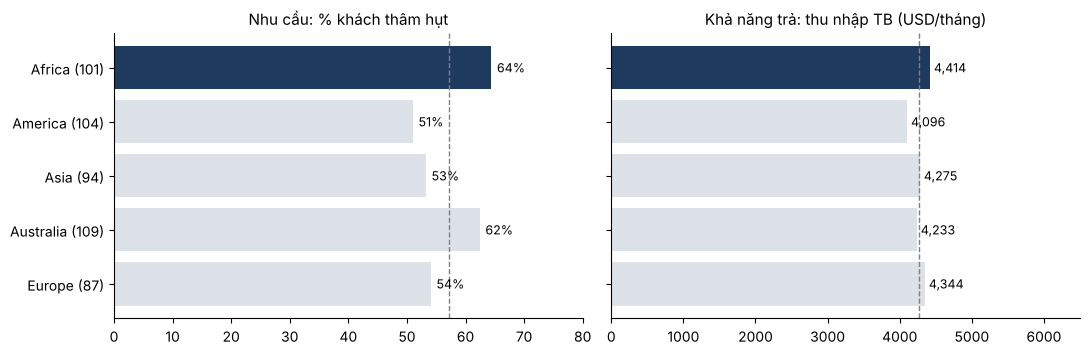

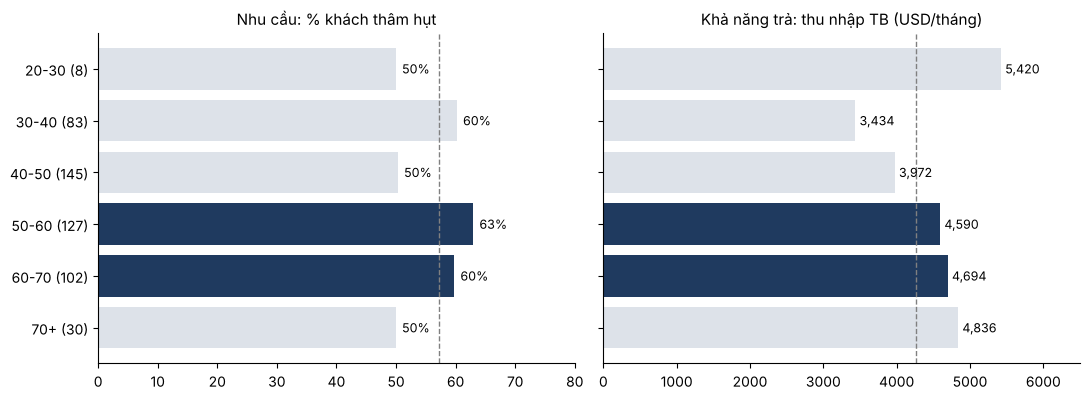

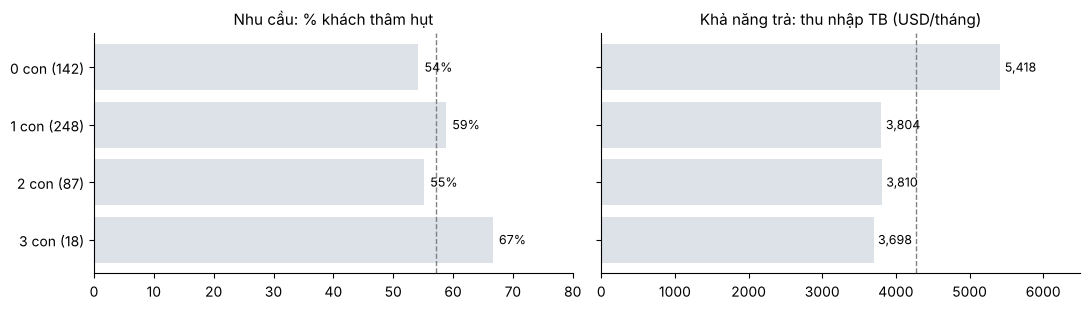

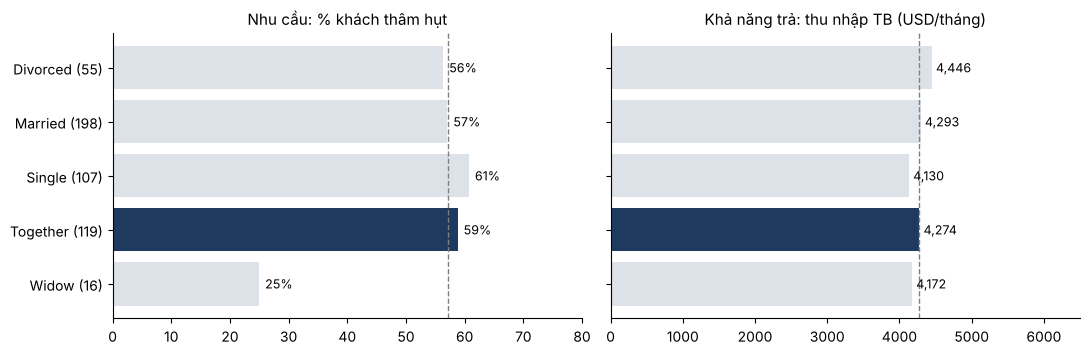

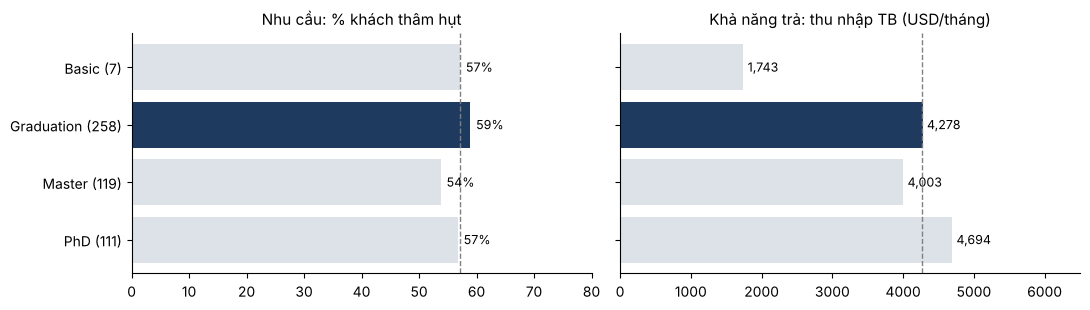

In [15]:
avg_income = overall.loc[0, 'avg_monthly_income']
avg_deficit = overall.loc[0, 'pct_deficit']

def plot_dimension(dim, filename):
    d = segments[segments['dimension'] == dim].sort_values('segment', ascending=False)
    good = (d['pct_deficit'] > avg_deficit) & (d['avg_monthly_income'] > avg_income)
    colors = [BLUE if g else GREY for g in good]
    labels = [f"{s} ({n})" for s, n in zip(d['segment'], d['customers'])]

    fig, axes = plt.subplots(1, 2, figsize=(11, 0.45 * len(d) + 1.4), sharey=True)
    axes[0].barh(labels, d['pct_deficit'], color=colors)
    axes[0].axvline(avg_deficit, color='grey', linestyle='--', linewidth=1)
    axes[0].set_title('Nhu cầu: % khách thâm hụt', fontsize=11)
    axes[0].set_xlim(0, 80)
    for i, v in enumerate(d['pct_deficit']):
        axes[0].text(v + 1, i, f'{v:.0f}%', va='center', fontsize=9)

    axes[1].barh(labels, d['avg_monthly_income'], color=colors)
    axes[1].axvline(avg_income, color='grey', linestyle='--', linewidth=1)
    axes[1].set_title('Khả năng trả: thu nhập TB (USD/tháng)', fontsize=11)
    axes[1].set_xlim(0, 6500)
    for i, v in enumerate(d['avg_monthly_income']):
        axes[1].text(v + 60, i, f'{v:,.0f}', va='center', fontsize=9)

    plt.tight_layout()
    plt.savefig(f'figures/{filename}.png', dpi=150, bbox_inches='tight')
    plt.show()


print(f'Trung bình ngân hàng: {avg_deficit:.0f}% thâm hụt, {avg_income:,.0f} USD/tháng (đường nét đứt)')
print('Màu xanh = nhóm vừa thâm hụt nhiều hơn, vừa thu nhập cao hơn trung bình')
for dim, filename in [('Châu lục', 'dim_region'), ('Độ tuổi', 'dim_age'), ('Số con', 'dim_children'),
                      ('Hôn nhân', 'dim_marital'), ('Học vấn', 'dim_education')]:
    plot_dimension(dim, filename)

**Đọc biểu đồ:**
- **Châu lục**: Phi và Úc thiếu tiền nhiều nhất (62-64% khách thâm hụt), nhưng thu nhập 5 châu gần như bằng nhau (4.100-4.400 USD). Châu lục chỉ nói về nhu cầu, không phân biệt được khả năng trả.
- **Độ tuổi**: nhóm 50-60 vừa thiếu tiền nhiều (63%) vừa thu nhập cao (4.590 USD). Nhóm 30-40 thiếu tiền (60%) nhưng thu nhập thấp nhất (3.430 USD).
- **Số con**: khách có con thiếu tiền nhiều hơn, nhưng thu nhập thấp hơn hẳn (khoảng 3.800 so với 5.420 USD/tháng của khách không con). Có nhu cầu nhưng rủi ro trả nợ cao hơn.
- **Hôn nhân**: Single và Together thâm hụt nhiều, Widow gần như không cần tín dụng (chỉ 16 khách).
- **Học vấn**: PhD thu nhập cao nhất, Basic chỉ có 7 khách và thu nhập thấp.

## 6. Trung bình nhóm có chọn đúng khách không?

Cách làm thường gặp: kết hợp 3 chiều ổn định, dễ thu thập (châu lục × tuổi × có con), rồi chọn những nhóm có dòng tiền ròng trung bình âm nhiều. Cách này chọn ra: **châu Phi 40-50 có con, châu Úc 40-50 có con, châu Á 30-40 có con**.

Kiểm tra lại từng khách trong 3 nhóm đó.

In [16]:
con.execute("""
CREATE OR REPLACE TABLE customer_flags AS
SELECT *
    , CASE WHEN net_flow < 0 THEN 1 ELSE 0 END AS f_need
    , CASE WHEN monthly_income >= 4000 THEN 1 ELSE 0 END AS f_income
    , CASE WHEN -net_flow <= monthly_income THEN 1 ELSE 0 END AS f_capacity
    , CASE WHEN age < 60 THEN 1 ELSE 0 END AS f_age
    , CASE WHEN children > 0 THEN 'Có con' ELSE 'Không con' END AS has_children
FROM customer_base
""")

combo = sql("""
SELECT region_name, age_group, has_children,
       COUNT(*) AS customers,
       AVG(monthly_income) AS avg_monthly_income,
       AVG(net_flow) AS avg_net_flow,
       SUM(f_need) AS need,
       SUM(f_need * f_income) AS need_and_income,
       SUM(f_need * f_income * f_capacity * f_age) AS pass_all
FROM customer_flags
WHERE (region_name = 'Africa'    AND age_group = '40-50' AND has_children = 'Có con')
   OR (region_name = 'Australia' AND age_group = '40-50' AND has_children = 'Có con')
   OR (region_name = 'Asia'      AND age_group = '30-40' AND has_children = 'Có con')
GROUP BY region_name, age_group, has_children
""")
combo.round(0)

,region_name,age_group,has_children,customers,avg_monthly_income,avg_net_flow,need,need_and_income,pass_all
0,Africa,40-50,Có con,29,3742.0,-1455.0,16.0,5.0,4.0
1,Asia,30-40,Có con,15,2760.0,-2023.0,10.0,1.0,1.0
2,Australia,40-50,Có con,23,3531.0,-1970.0,15.0,5.0,2.0


In [17]:
print('Khách trong 3 nhóm:', combo['customers'].sum())
print('Có nhu cầu (thâm hụt):', combo['need'].sum())
print('Có nhu cầu và thu nhập >= 4.000 USD:', combo['need_and_income'].sum())
print('Đạt cả 4 điều kiện:', combo['pass_all'].sum())

Khách trong 3 nhóm: 67
Có nhu cầu (thâm hụt): 41.0
Có nhu cầu và thu nhập >= 4.000 USD: 11.0
Đạt cả 4 điều kiện: 7.0


3 nhóm này có 67 khách, nhưng **chỉ 7 khách** vừa thiếu tiền vừa đủ khả năng trả. Lý do: nhóm có con thiếu tiền nhiều nhưng thu nhập trung bình chỉ khoảng 2.800-3.700 USD, dưới mức trung bình ngân hàng.

Trung bình nhóm hữu ích để **hiểu thị trường và viết thông điệp**, nhưng để **chọn người được mời** thì phải xét **từng khách**.

## 7. Lọc khách mục tiêu theo từng khách hàng

4 điều kiện:
1. **Có nhu cầu**: `net_flow < 0`
2. **Thu nhập đủ**: `monthly_income >= 4000`
3. **Trả được**: phần thiếu hụt mỗi tháng không vượt quá 1 tháng thu nhập
4. **Còn bán chéo**: dưới 60 tuổi

In [18]:
funnel = sql("""
SELECT
      COUNT(*) AS "Khách sau làm sạch"
    , SUM(f_need) AS "1. Có nhu cầu"
    , SUM(f_need * f_income) AS "2. Thu nhập >= 4.000"
    , SUM(f_need * f_income * f_capacity) AS "3. Thiếu hụt <= thu nhập"
    , SUM(f_need * f_income * f_capacity * f_age) AS "4. Dưới 60 tuổi"
FROM customer_flags
""").T.reset_index()
funnel.columns = ['step', 'customers']
funnel['customers'] = funnel['customers'].astype(int)
funnel

,step,customers
0,Khách sau làm sạch,495
1,1. Có nhu cầu,283
2,2. Thu nhập >= 4.000,147
3,3. Thiếu hụt <= thu nhập,102
4,4. Dưới 60 tuổi,69


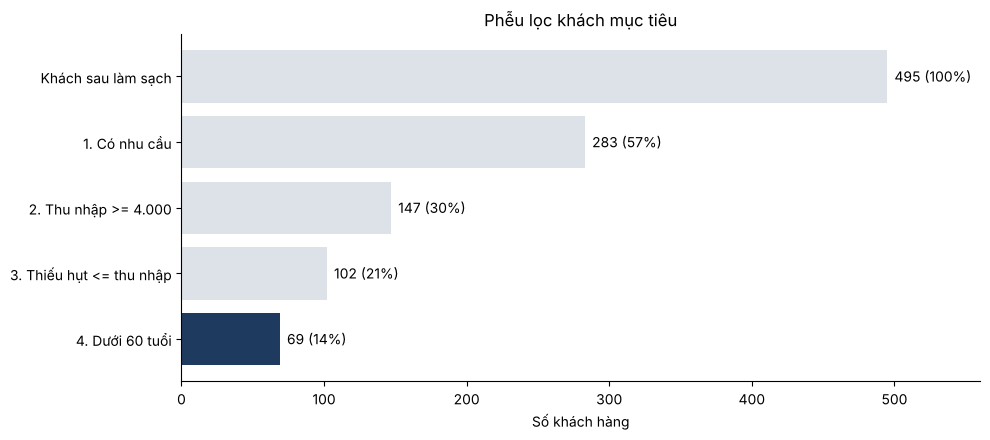

In [19]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [GREY, GREY, GREY, GREY, BLUE]
ax.barh(funnel['step'][::-1], funnel['customers'][::-1], color=colors[::-1])
for i, v in enumerate(funnel['customers'][::-1]):
    ax.text(v + 5, i, f'{v} ({v / funnel["customers"][0]:.0%})', va='center')
ax.set_xlabel('Số khách hàng')
ax.set_title('Phễu lọc khách mục tiêu')
ax.set_xlim(0, 560)
plt.tight_layout()
plt.savefig('figures/funnel.png', dpi=150, bbox_inches='tight')
plt.show()

In [20]:
con.execute("""
CREATE OR REPLACE TABLE target_customers AS
SELECT ID, region_name, age, age_group, education, marital_status, children,
       ROUND(monthly_income, 0) AS monthly_income,
       ROUND(net_flow, 0) AS net_flow,
       ROUND(-net_flow / monthly_income, 2) AS deficit_to_income
FROM customer_flags
WHERE f_need = 1 AND f_income = 1 AND f_capacity = 1 AND f_age = 1
ORDER BY deficit_to_income DESC
""")
targets = sql("SELECT * FROM target_customers")
targets.to_csv('output/target_customers.csv', index=False)
print(len(targets), 'khách mục tiêu')
targets.head(10)

69 khách mục tiêu


,ID,region_name,age,age_group,education,marital_status,children,monthly_income,net_flow,deficit_to_income
0,318,Asia,35,30-40,Graduation,Single,1,5542.0,-5493.0,0.99
1,70,Africa,50,50-60,Graduation,Together,3,6238.0,-6047.0,0.97
2,125,America,37,30-40,Graduation,Single,0,8498.0,-8120.0,0.96
3,352,Europe,34,30-40,Graduation,Married,1,5996.0,-5673.0,0.95
4,223,Asia,50,50-60,PhD,Together,2,6469.0,-6088.0,0.94
5,341,Europe,32,30-40,Graduation,Single,0,5721.0,-5235.0,0.92
6,267,Africa,57,50-60,Graduation,Married,0,6677.0,-6105.0,0.91
7,293,Europe,40,40-50,Graduation,Married,0,6875.0,-6250.0,0.91
8,175,Australia,53,50-60,Graduation,Single,1,4340.0,-3873.0,0.89
9,448,Africa,56,50-60,Graduation,Single,0,6771.0,-6045.0,0.89


In [21]:
size = sql("""
SELECT COUNT(*) AS targets,
       AVG(monthly_income) AS avg_monthly_income,
       AVG(-net_flow) AS avg_monthly_gap,
       SUM(-net_flow) AS total_monthly_gap
FROM target_customers
""")
size.round(0)

,targets,avg_monthly_income,avg_monthly_gap,total_monthly_gap
0,69,5983.0,3094.0,213452.0


69 khách (14% tập khách), thu nhập TB gần 6.000 USD/tháng, mỗi tháng thiếu khoảng 3.100 USD. Tổng phần thiếu hụt khoảng **213 nghìn USD/tháng**: đây là quy mô chi tiêu có thể chuyển sang thẻ tín dụng nếu khách nhận lời (ước tính trần, chưa tính tỷ lệ nhận lời).

## 8. Khách mục tiêu nằm ở đâu?

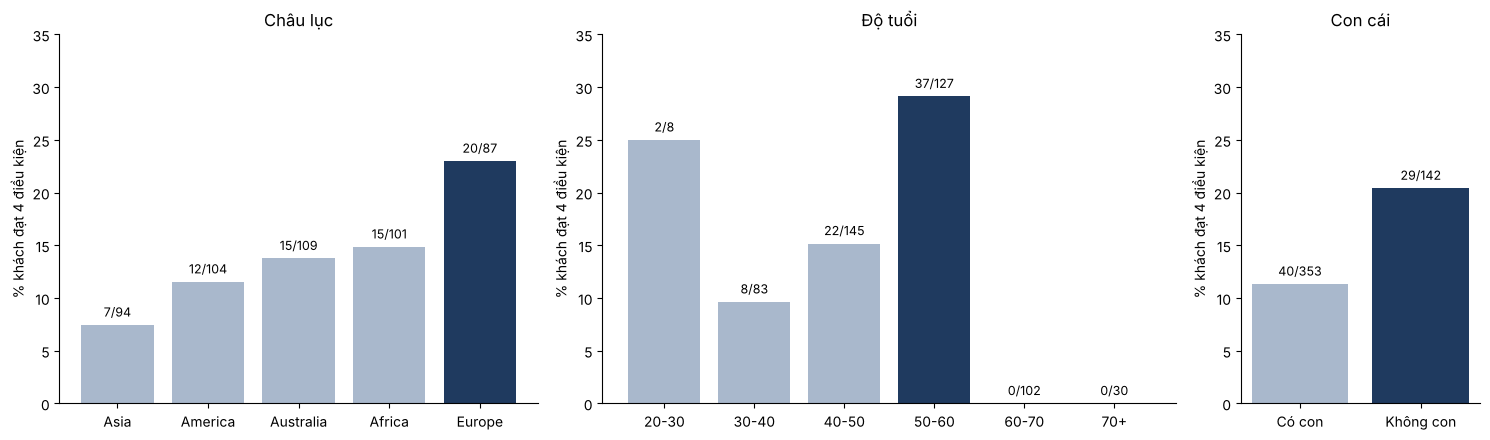

In [22]:
by_region = sql("""
SELECT region_name, COUNT(*) AS customers, SUM(f_need * f_income * f_capacity * f_age) AS targets
FROM customer_flags GROUP BY region_name
""")
by_region['pct'] = by_region['targets'] / by_region['customers'] * 100
by_region = by_region.sort_values('pct')

by_age = sql("""
SELECT age_group, COUNT(*) AS customers, SUM(f_need * f_income * f_capacity * f_age) AS targets
FROM customer_flags GROUP BY age_group ORDER BY age_group
""")
by_age['pct'] = by_age['targets'] / by_age['customers'] * 100

by_kids = sql("""
SELECT has_children, COUNT(*) AS customers, SUM(f_need * f_income * f_capacity * f_age) AS targets
FROM customer_flags GROUP BY has_children ORDER BY has_children
""")
by_kids['pct'] = by_kids['targets'] / by_kids['customers'] * 100

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), gridspec_kw={'width_ratios': [5, 6, 2.5]})
for ax, d, col, title in [(axes[0], by_region, 'region_name', 'Châu lục'),
                          (axes[1], by_age, 'age_group', 'Độ tuổi'),
                          (axes[2], by_kids, 'has_children', 'Con cái')]:
    top = d['pct'].max()
    ax.bar(d[col], d['pct'], color=[BLUE if p == top else MINT for p in d['pct']])
    for i, (p, t, n) in enumerate(zip(d['pct'], d['targets'], d['customers'])):
        ax.text(i, p + 0.8, f'{int(t)}/{n}', ha='center', fontsize=9)
    ax.set_title(title)
    ax.set_ylabel('% khách đạt 4 điều kiện')
    ax.set_ylim(0, 35)
plt.tight_layout()
plt.savefig('figures/targets_where.png', dpi=150, bbox_inches='tight')
plt.show()

- **Châu Âu** có tỷ lệ khách mục tiêu cao nhất (23%), dù trung bình nhóm cho thấy châu Âu ít thiếu tiền nhất. Trung bình nhóm đã che mất những khách thu nhập cao đang thiếu tiền.
- **50-60 tuổi** chiếm hơn một nửa danh sách (37/69). Nhóm 60+ bị loại vì điều kiện tuổi.
- **Khách không con** đạt tỷ lệ cao hơn (20% so với 11%) vì thu nhập cao hơn.

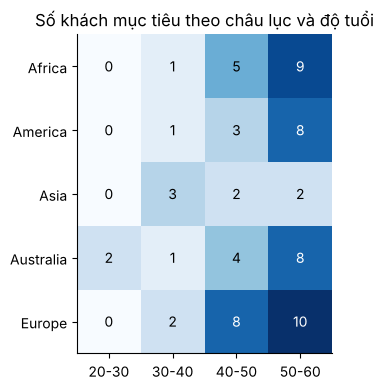

In [23]:
heat = sql("""
SELECT region_name, age_group, SUM(f_need * f_income * f_capacity * f_age) AS targets
FROM customer_flags
WHERE age < 60
GROUP BY region_name, age_group
""").pivot(index='region_name', columns='age_group', values='targets').fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.imshow(heat.values, cmap='Blues')
ax.set_xticks(range(len(heat.columns)))
ax.set_xticklabels(heat.columns)
ax.set_yticks(range(len(heat.index)))
ax.set_yticklabels(heat.index)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, v, ha='center', va='center', color='white' if v >= 7 else 'black')
ax.set_title('Số khách mục tiêu theo châu lục và độ tuổi')
plt.tight_layout()
plt.savefig('figures/heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Kết luận và hành động đề xuất

1. **Mời 69 khách trong danh sách** (`output/target_customers.csv`) mở thẻ tín dụng, ưu tiên châu Âu, châu Phi, châu Úc và nhóm 50-60 tuổi.
2. **Chạy thử trước khi mở rộng**: chia danh sách làm 2 nhóm, chỉ mời 1 nhóm, so sánh tỷ lệ mở thẻ và mức chi tiêu sau 3 tháng.
3. **Không mời ngay nhóm có nhu cầu nhưng thu nhập thấp** (136 khách thâm hụt có thu nhập dưới 4.000 USD hoặc thiếu dữ liệu thu nhập): cập nhật lại thu nhập, kiểm tra lịch sử tín dụng trước.
4. **Theo dõi**: tỷ lệ mở thẻ, tỷ lệ kích hoạt, dư nợ trung bình, tỷ lệ trả chậm trên 30 ngày, và số khách chuyển tiếp sang vay mua xe, mua nhà sau 12 tháng.

**Giới hạn:**
- Chỉ có 4 tháng giao dịch, tháng 4 chưa đủ tháng.
- Chưa có lịch sử tín dụng (CIC), khoản nợ hiện có, hay thu nhập đã xác minh.
- Ngưỡng 4.000 USD và 60 tuổi là giả định; ngân hàng thật sẽ lấy theo chính sách cấp tín dụng.